<a href="https://colab.research.google.com/github/LucelySM-creator/Mercado-de-Trabalho/blob/main/Taxa%20de%20desemprego%20-%20R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Lista de pacotes necessários
pacotes <- c("readxl", "dplyr", "tidyr", "ggplot2", "patchwork", "scales", "knitr")

# Instala os pacotes que ainda não estão instalados
pacotes_faltantes <- pacotes[!(pacotes %in% installed.packages()[, "Package"])]
if(length(pacotes_faltantes) > 0) {
  install.packages(pacotes_faltantes, repos = "https://cloud.r-project.org/")
}

# Carrega as bibliotecas
library(readxl)
library(dplyr)
library(tidyr)
library(ggplot2)
library(patchwork)
library(scales)
library(knitr)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`
• `` -> `...8`
• `` -> `...9`
• `` -> `...10`
• `` -> `...11`
• `` -> `...12`
• `` -> `...13`
• `` -> `...14`
• `` -> `...15`
• `` -> `...16`
• `` -> `...17`
• `` -> `...18`
• `` -> `...19`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`


                Indicador Variação_Percentual
1 Força de Trabalho Total              +0.18%
2                  Homens              +0.18%
3                Mulheres              +0.18%
4 Faixa Etária Referência              +0.18%


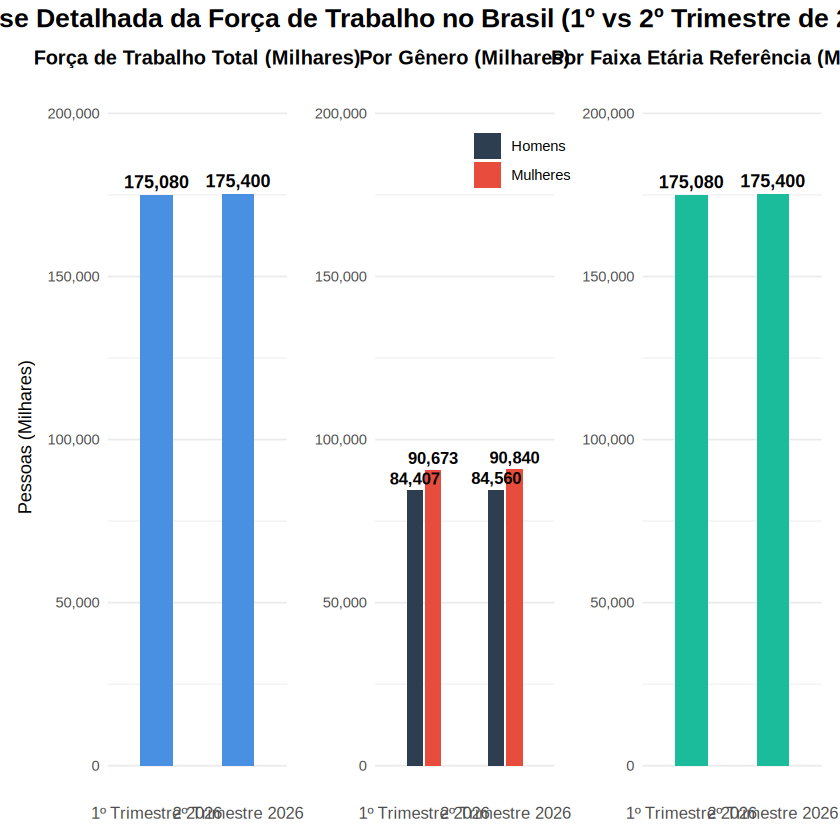

In [14]:
# Instalação e Carregamento de Pacotes
pacotes <- c("readxl", "dplyr", "tidyr", "ggplot2", "patchwork", "scales", "kableExtra")
pacotes_faltantes <- pacotes[!(pacotes %in% installed.packages()[, "Package"])]
if(length(pacotes_faltantes) > 0) {
  install.packages(pacotes_faltantes, repos = "https://cloud.r-project.org/")
}

library(readxl)
library(dplyr)
library(tidyr)
library(ggplot2)
library(patchwork)
library(scales)
library(kableExtra)

# Função para extrair dados da linha "Brasil" após o termo de busca
extrair_taxa_excel <- function(caminho_arquivo, termo_busca, num_colunas) {
  df_excel <- read_excel(caminho_arquivo, col_names = FALSE)

  # Localiza a linha inicial pelo termo de busca
  linha_inicio <- which(apply(df_excel, 1, function(row) any(grepl(termo_busca, row, fixed = TRUE))))
  if (length(linha_inicio) == 0) lambda_inicio <- 1 else linha_inicio <- linha_inicio[1]

  # Busca a linha "Brasil" a partir da linha de início
  sub_df <- df_excel[linha_inicio:nrow(df_excel), ]
  rel_brasil <- which(apply(sub_df, 1, function(row) any(grepl("Brasil", row, fixed = TRUE))))

  if (length(rel_brasil) == 0) {
    linha_brasil <- linha_inicio + 4
  } else {
    linha_brasil <- linha_inicio + rel_brasil[1] - 1
  }

  # Extrai as colunas numéricas (no R o índice começa em 1)
  dados_brasil <- as.character(df_excel[linha_brasil, 2:(num_colunas + 1)])
  valores <- suppressWarnings(as.numeric(dados_brasil))
  valores[is.na(valores)] <- 0.0

  return(valores)
}

# Caminhos dos arquivos
arq_sexo <- "/content/Tabela 4093 SIDRA IBGE.xlsx"
arq_idade <- "/content/Tabela 4094 SIDRA IBGE.xlsx"

# TABELA 4093: Extraindo dados de sexo
dados_sexo <- extrair_taxa_excel(arq_sexo, "Pessoas de 14 anos ou mais de idade", 18)

taxa_total_1t26  <- dados_sexo[13]
taxa_homem_1t26  <- dados_sexo[14]
taxa_mulher_1t26 <- dados_sexo[15]
taxa_total_2t26  <- dados_sexo[16]
taxa_homem_2t26  <- dados_sexo[17]
taxa_mulher_2t26 <- dados_sexo[18]

# TABELA 4094: Extraindo dados de idade
dados_idade <- extrair_taxa_excel(arq_idade, "Pessoas de 14 anos ou mais de idade", 6)

taxa_idade_1t26 <- dados_idade[5]
taxa_idade_2t26 <- dados_idade[6]

# Preparação dos DataFrames
trimestres <- c("1º Trimestre 2026", "2º Trimestre 2026")
limite_y <- max(taxa_mulher_1t26, taxa_total_1t26, taxa_idade_1t26, 100) * 1.15

df_tot <- data.frame(
  Trimestre = factor(trimestres, levels = trimestres),
  Valor = c(taxa_total_1t26, taxa_total_2t26)
)

df_gen <- data.frame(
  Trimestre = rep(factor(trimestres, levels = trimestres), each = 2),
  Genero = rep(c("Homens", "Mulheres"), times = 2),
  Valor = c(taxa_homem_1t26, taxa_mulher_1t26, taxa_homem_2t26, taxa_mulher_2t26)
)

df_id <- data.frame(
  Trimestre = factor(trimestres, levels = trimestres),
  Valor = c(taxa_idade_1t26, taxa_idade_2t26)
)

tema_base <- theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 12, hjust = 0.5),
    axis.title.x = element_blank(),
    axis.text.x = element_text(size = 10),
    panel.grid.major.x = element_blank()
  )

# Gráficos
g1 <- ggplot(df_tot, aes(x = Trimestre, y = Valor)) +
  geom_col(fill = "#4a90e2", width = 0.4) +
  geom_text(aes(label = comma(Valor)), vjust = -0.5, fontface = "bold", size = 3.8) +
  scale_y_continuous(limits = c(0, limite_y), labels = comma) +
  labs(title = "Força de Trabalho Total (Milhares)", y = "Pessoas (Milhares)") +
  tema_base

g2 <- ggplot(df_gen, aes(x = Trimestre, y = Valor, fill = Genero)) +
  geom_col(position = position_dodge(width = 0.45), width = 0.4) +
  geom_text(aes(label = comma(Valor)), position = position_dodge(width = 0.45), vjust = -0.5, fontface = "bold", size = 3.5) +
  scale_fill_manual(values = c("Homens" = "#2c3e50", "Mulheres" = "#e74c3c")) +
  scale_y_continuous(limits = c(0, limite_y), labels = comma) +
  labs(title = "Por Gênero (Milhares)", fill = "") +
  tema_base +
  theme(axis.title.y = element_blank(), legend.position = c(0.85, 0.9))

g3 <- ggplot(df_id, aes(x = Trimestre, y = Valor)) +
  geom_col(fill = "#1abc9c", width = 0.4) +
  geom_text(aes(label = comma(Valor)), vjust = -0.5, fontface = "bold", size = 3.8) +
  scale_y_continuous(limits = c(0, limite_y), labels = comma) +
  labs(title = "Por Faixa Etária Referência (Milhares)") +
  tema_base +
  theme(axis.title.y = element_blank())

# Junção dos gráficos
painel_final <- (g1 | g2 | g3) +
  plot_annotation(
    title = "Análise Detalhada da Força de Trabalho no Brasil (1º vs 2º Trimestre de 2026)",
    theme = theme(plot.title = element_text(size = 16, face = "bold", hjust = 0.5))
  )

print(painel_final)

# Tabela de Variações Percentuais
var_total  <- ((taxa_total_2t26 - taxa_total_1t26) / taxa_total_1t26) * 100
var_homem  <- ((taxa_homem_2t26 - taxa_homem_1t26) / taxa_homem_1t26) * 100
var_mulher <- ((taxa_mulher_2t26 - taxa_mulher_1t26) / taxa_mulher_1t26) * 100
var_idade  <- ((taxa_idade_2t26 - taxa_idade_1t26) / taxa_idade_1t26) * 100

df_resumo_var <- data.frame(
  Indicador = c("Força de Trabalho Total", "Homens", "Mulheres", "Faixa Etária Referência"),
  Variação_Percentual = sprintf("%+.2f%%", c(var_total, var_homem, var_mulher, var_idade)),
  check.names = FALSE
)

print(df_resumo_var)


In [6]:
var_total  <- ((taxa_total_2t26 - taxa_total_1t26) / taxa_total_1t26) * 100
var_homem  <- ((taxa_homem_2t26 - taxa_homem_1t26) / taxa_homem_1t26) * 100
var_mulher <- ((taxa_mulher_2t26 - taxa_mulher_1t26) / taxa_mulher_1t26) * 100
var_idade  <- ((taxa_idade_2t26 - taxa_idade_1t26) / taxa_idade_1t26) * 100

cat("Variação Percentual (1º Trimestre 2026 vs 2º Trimestre 2026):\n\n")
cat(sprintf("Força de Trabalho Total: %+.2f%%\n", var_total))
cat(sprintf("Homens:                  %+.2f%%\n", var_homem))
cat(sprintf("Mulheres:                %+.2f%%\n", var_mulher))
cat(sprintf("Faixa Etária Referência: %+.2f%%\n", var_idade))


Variação Percentual (1º Trimestre 2026 vs 2º Trimestre 2026):

Força de Trabalho Total: +0.18%
Homens:                  +0.18%
Mulheres:                +0.18%
Faixa Etária Referência: +0.18%


New names:
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`
• `` -> `...8`
• `` -> `...9`
• `` -> `...10`
• `` -> `...11`
• `` -> `...12`
• `` -> `...13`
• `` -> `...14`
• `` -> `...15`
• `` -> `...16`
• `` -> `...17`
• `` -> `...18`
• `` -> `...19`




Table: Tabela 4093 - Primeiras 10 linhas

|Tabela 4093 - Pessoas de 14 anos ou mais de idade, total, na força de trabalho, ocupadas, desocupadas, fora da força de trabalho, em situação de informalidade e respectivas taxas e níveis, por sexo |...2              |...3   |...4     |...5              |...6   |...7     |...8              |...9   |...10    |...11             |...12  |...13    |...14             |...15  |...16    |...17             |...18  |...19    |
|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:-----------------|:------|:--------|:-----------------|:------|:--------|:-----------------|:------|:--------|:-----------------|:------|:--------|:-----------------|:------|:--------|:-----------------|:------|:--------|
|Variável - Pessoas de 14 anos ou mais de idade (Mil pessoas)                                                 

New names:
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`




Table: Tabela 4094 - Primeiras 15 linhas

|Tabela 4094 - Pessoas de 14 anos ou mais de idade, total, na força de trabalho, ocupadas, desocupadas, fora da força de trabalho, em situação de informalidade e respectivas taxas e níveis, por grupo de idade |...2                       |...3              |...4              |...5              |...6              |...7              |
|:---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:--------------------------|:-----------------|:-----------------|:-----------------|:-----------------|:-----------------|
|Variável - Pessoas de 14 anos ou mais de idade (Mil pessoas)                                                                                                                                                    |                           |                  |                  |            

New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`




Table: Variação Percentual Trimestral da População (Tabela 4094 - Total)

|     Trimestre     | Pessoas (Milhares) | Variação Anterior (%) |
|:-----------------:|:------------------:|:---------------------:|
| 1º trimestre 2025 |      173,761       |           -           |
| 2º trimestre 2025 |      174,079       |        +0.18%         |
| 3º trimestre 2025 |      174,411       |        +0.19%         |
| 4º trimestre 2025 |      174,747       |        +0.19%         |
| 1º trimestre 2026 |      175,080       |        +0.19%         |
| 2º trimestre 2026 |      175,400       |        +0.18%         |

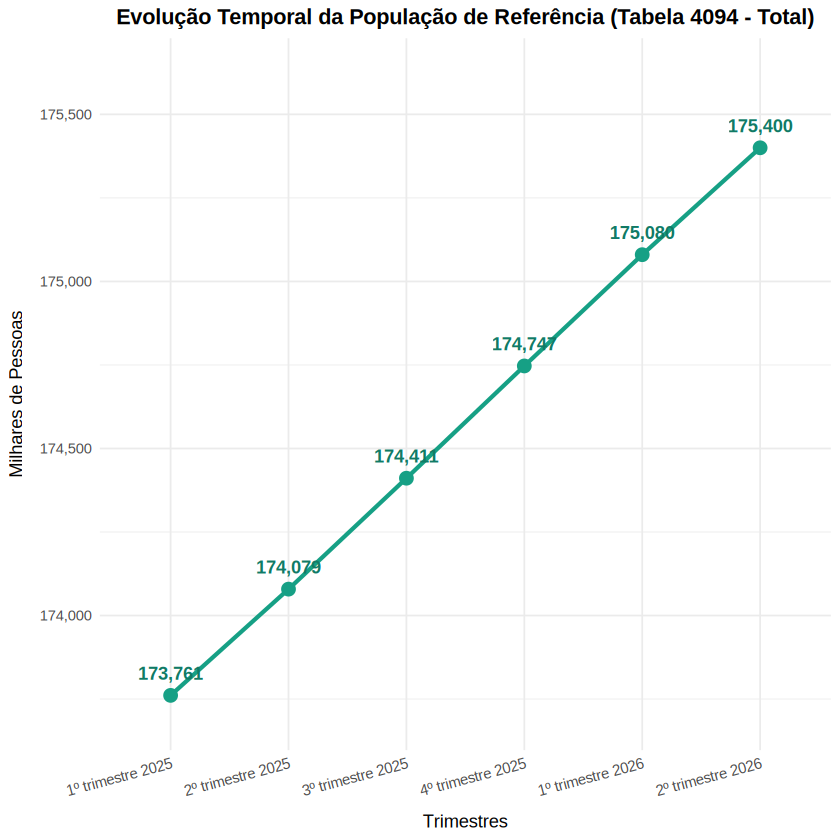

In [7]:
# Visualização limpa das primeiras linhas das tabelas
df_tabela_4093 <- read_excel(arq_sexo) %>% head(10)
df_tabela_4093[is.na(df_tabela_4093)] <- ""
kable(df_tabela_4093, caption = "Tabela 4093 - Primeiras 10 linhas")

df_tabela_4094 <- read_excel(arq_idade) %>% head(15)
df_tabela_4094[is.na(df_tabela_4094)] <- ""
kable(df_tabela_4094, caption = "Tabela 4094 - Primeiras 15 linhas")

# Processamento dinâmico da Tabela 4094 para série temporal
df_raw_4094 <- read_excel(arq_idade, col_names = FALSE)

# Linha 4 e 5 no R correspondem aos índices 3 e 4 do Python
trimestres_cabecalho <- as.character(df_raw_4094[4, -1])
# Preenche valores vazios para frente (equivalente ao ffill)
trimestres_cabecalho <- tidyr::fill(data.frame(t = trimestres_cabecalho), t, .direction = "down")$t
grupos_idade_cabecalho <- as.character(df_raw_4094[5, -1])

# Captura a linha do Brasil
linha_brasil_idx <- which(df_raw_4094[[1]] == "Brasil")[1]
valores_brasil <- suppressWarnings(as.numeric(as.character(df_raw_4094[linha_brasil_idx, -1])))
valores_brasil[is.na(valores_brasil)] <- 0.0

df_analise_4094 <- data.frame(
  Trimestre = factor(trimestres_cabecalho, levels = unique(trimestres_cabecalho)),
  Grupo_Idade = grupos_idade_cabecalho,
  Pessoas_Milhares = valores_brasil
)

# Filtrando apenas o 'Total'
df_total_4094 <- df_analise_4094 %>%
  filter(Grupo_Idade == "Total") %>%
  mutate(
    Variacao_Anterior = (Pessoas_Milhares / lag(Pessoas_Milhares) - 1) * 100
  )

# Gráfico de linha da evolução temporal
ggplot(df_total_4094, aes(x = Trimestre, y = Pessoas_Milhares, group = 1)) +
  geom_line(color = "#16a085", linewidth = 1.2) +
  geom_point(color = "#16a085", size = 3.5) +
  geom_text(aes(label = comma(Pessoas_Milhares)), vjust = -1.2, fontface = "bold", color = "#117a65") +
  scale_y_continuous(labels = comma, expand = expansion(mult = c(0.1, 0.2))) +
  labs(
    title = "Evolução Temporal da População de Referência (Tabela 4094 - Total)",
    x = "Trimestres",
    y = "Milhares de Pessoas"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 13, hjust = 0.5),
    axis.text.x = element_text(angle = 15, hjust = 1)
  )

# Tabela final formatada com a variação percentual trimestral
tabela_variacao_final <- df_total_4094 %>%
  transmute(
    Trimestre = Trimestre,
    `Pessoas (Milhares)` = comma(Pessoas_Milhares),
    `Variação Anterior (%)` = ifelse(is.na(Variacao_Anterior), "-", sprintf("%+.2f%%", Variacao_Anterior))
  )

kable(tabela_variacao_final, align = "c", caption = "Variação Percentual Trimestral da População (Tabela 4094 - Total)")



In [15]:
install.packages("rmarkdown")
install.packages("tinytex")
tinytex::install_tinytex()


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

tlmgr option sys_bin ~/bin

tlmgr option repository 'https://tlnet.yihui.org'

tlmgr update --list

You may have to restart your system after installing TinyTeX to make sure ~/bin appears in your PATH variable (https://github.com/rstudio/tinytex/issues/16).

